**Assignment 2 — Task 1: Model Building**

---

**1. Introduction**

In [9]:
# ── Imports ───────────────────────────────────────────────────────────────────
import os, json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models, optimizers, callbacks
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import ResNet50
from sklearn.metrics import classification_report, confusion_matrix

# Reproducibility
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

print(f"TensorFlow : {tf.__version__}")
print(f"GPU available : {len(tf.config.list_physical_devices('GPU')) > 0}")

TensorFlow : 2.10.0
GPU available : True


In [10]:
# ── Load config from A1 Task 2 ────────────────────────────────────────────────
with open('dataset_config.json') as f:
    cfg = json.load(f)

TRAIN_DIR   = cfg['TRAIN_DIR']
VAL_DIR     = cfg['VAL_DIR']
TEST_DIR    = cfg['TEST_DIR']
IMG_SIZE    = tuple(cfg['IMG_SIZE'])
BATCH_SIZE  = cfg['BATCH_SIZE']
N_CLASSES   = cfg['N_CLASSES']
CLASSES     = cfg['CLASSES']
CLASS_WEIGHTS = {int(k): v for k, v in cfg['CLASS_WEIGHTS'].items()}

print(f"Classes ({N_CLASSES}): {CLASSES}")
print(f"Image size  : {IMG_SIZE}")
print(f"Batch size  : {BATCH_SIZE}")

Classes (15): ['Beetle', 'Butterfly', 'Cat', 'Cow', 'Dog', 'Elephant', 'Gorilla', 'Hippo', 'Lizard', 'Monkey', 'Mouse', 'Panda', 'Spider', 'Tiger', 'Zebra']
Image size  : (224, 224)
Batch size  : 32


In [11]:
# ── Rebuild data generators ───────────────────────────────────────────────────
train_datagen = ImageDataGenerator(
    rescale=1./255, rotation_range=20, width_shift_range=0.15,
    height_shift_range=0.15, shear_range=0.1, zoom_range=0.2,
    horizontal_flip=True, brightness_range=[0.8, 1.2], fill_mode='nearest'
)
val_test_datagen = ImageDataGenerator(rescale=1./255)

train_gen = train_datagen.flow_from_directory(
    TRAIN_DIR, target_size=IMG_SIZE, batch_size=BATCH_SIZE,
    class_mode='categorical', seed=SEED, shuffle=True
)
val_gen = val_test_datagen.flow_from_directory(
    VAL_DIR, target_size=IMG_SIZE, batch_size=BATCH_SIZE,
    class_mode='categorical', seed=SEED, shuffle=False
)
test_gen = val_test_datagen.flow_from_directory(
    TEST_DIR, target_size=IMG_SIZE, batch_size=BATCH_SIZE,
    class_mode='categorical', seed=SEED, shuffle=False
)
print("Data generators ready.")

Found 30000 images belonging to 15 classes.
Found 2000 images belonging to 15 classes.
Found 2407 images belonging to 15 classes.
Data generators ready.


---
**2. Model 1 — Custom CNN**

*2.1 Architecture*

In [12]:
def build_custom_cnn(n_classes, input_shape=(224, 224, 3)):
    """Custom CNN — 4 convolutional blocks + dense head."""
    inp = keras.Input(shape=input_shape)
    x = inp

    for filters in [32, 64, 128, 256]:
        x = layers.Conv2D(filters, (3,3), padding='same')(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation('relu')(x)
        x = layers.Conv2D(filters, (3,3), padding='same')(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation('relu')(x)
        x = layers.MaxPooling2D(2, 2)(x)
        x = layers.Dropout(0.25)(x)

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(512, activation='relu')(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dropout(0.5)(x)
    out = layers.Dense(n_classes, activation='softmax')(x)

    model = models.Model(inp, out, name='Custom_CNN')
    return model

cnn_model = build_custom_cnn(N_CLASSES)
cnn_model.summary()

Model: "Custom_CNN"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_2 (InputLayer)        [(None, 224, 224, 3)]     0         
                                                                 
 conv2d_8 (Conv2D)           (None, 224, 224, 32)      896       
                                                                 
 batch_normalization_9 (Batc  (None, 224, 224, 32)     128       
 hNormalization)                                                 
                                                                 
 activation_8 (Activation)   (None, 224, 224, 32)      0         
                                                                 
 conv2d_9 (Conv2D)           (None, 224, 224, 32)      9248      
                                                                 
 batch_normalization_10 (Bat  (None, 224, 224, 32)     128       
 chNormalization)                                       

*2.2 Training Methodology*

In [13]:
# ── Compile CNN ───────────────────────────────────────────────────────────────
cnn_model.compile(
    optimizer=optimizers.Adam(learning_rate=1e-3),
    loss='categorical_crossentropy',
    metrics=['accuracy', tf.keras.metrics.TopKCategoricalAccuracy(k=3, name='top3_acc')]
)

cnn_callbacks = [
    callbacks.EarlyStopping(
        monitor='val_loss', patience=10, restore_best_weights=True, verbose=1
    ),
    callbacks.ReduceLROnPlateau(
        monitor='val_loss', factor=0.5, patience=5, min_lr=1e-7, verbose=1
    ),
    callbacks.ModelCheckpoint(
        'best_custom_cnn.keras', monitor='val_accuracy',
        save_best_only=True, verbose=1
    )
]

print("Custom CNN compiled and ready to train.")

Custom CNN compiled and ready to train.


In [14]:
# ── Train CNN ─────────────────────────────────────────────────────────────────
EPOCHS_CNN = 20
t0 = time.time()

history_cnn = cnn_model.fit(
    train_gen,
    epochs          = EPOCHS_CNN,
    validation_data = val_gen,
    callbacks       = cnn_callbacks,
    class_weight    = CLASS_WEIGHTS,
    verbose         = 1
)

cnn_train_time = time.time() - t0
print(f"\nCNN training completed in {cnn_train_time/60:.1f} minutes.")
print(f"Best val_accuracy: {max(history_cnn.history['val_accuracy']):.4f}")

Epoch 1/20
938/938 [==============================] - ETA: 0s - loss: 2.4208 - accuracy: 0.2407 - top3_acc: 0.4923
Epoch 1: val_accuracy improved from -inf to 0.27300, saving model to best_custom_cnn.keras
938/938 [==============================] - 642s 680ms/step - loss: 2.4208 - accuracy: 0.2407 - top3_acc: 0.4923 - val_loss: 2.3177 - val_accuracy: 0.2730 - val_top3_acc: 0.5445 - lr: 0.0010
Epoch 2/20
938/938 [==============================] - ETA: 0s - loss: 1.8645 - accuracy: 0.3944 - top3_acc: 0.6806
Epoch 2: val_accuracy improved from 0.27300 to 0.27750, saving model to best_custom_cnn.keras
938/938 [==============================] - 406s 433ms/step - loss: 1.8645 - accuracy: 0.3944 - top3_acc: 0.6806 - val_loss: 3.3775 - val_accuracy: 0.2775 - val_top3_acc: 0.5410 - lr: 0.0010
Epoch 3/20
938/938 [==============================] - ETA: 0s - loss: 1.6115 - accuracy: 0.4748 - top3_acc: 0.7545
Epoch 3: val_accuracy improved from 0.27750 to 0.43250, saving model to best_custom_cnn.ke

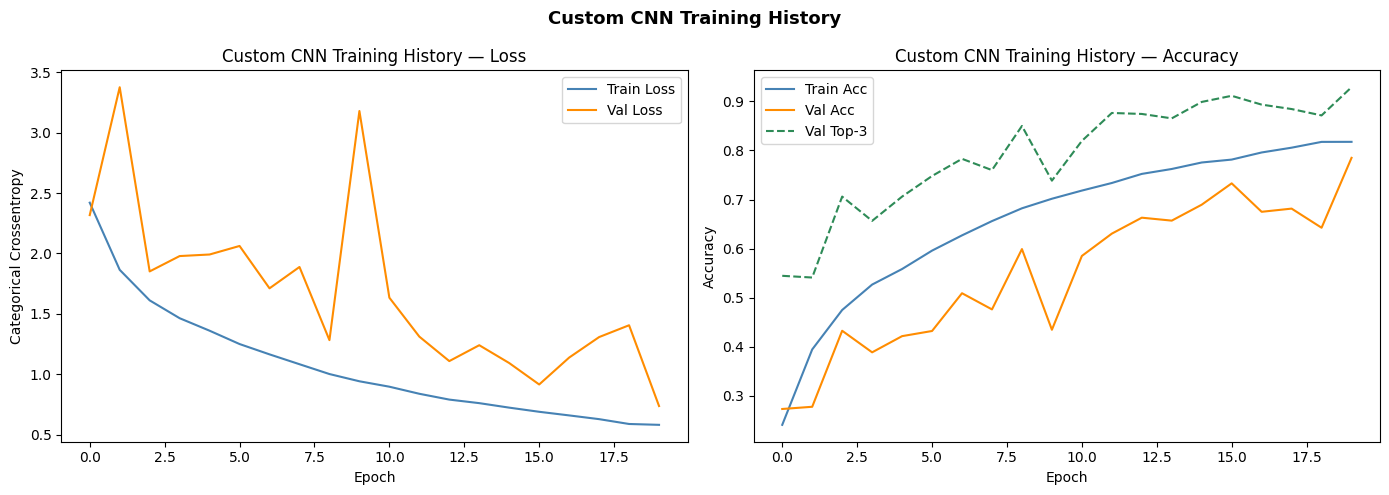

In [15]:
# ── Plot CNN training curves ───────────────────────────────────────────────────
def plot_history(hist, title, fname):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    axes[0].plot(hist.history['loss'],     label='Train Loss',  color='steelblue')
    axes[0].plot(hist.history['val_loss'], label='Val Loss',    color='darkorange')
    axes[0].set_title(f'{title} — Loss')
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Categorical Crossentropy')
    axes[0].legend()

    axes[1].plot(hist.history['accuracy'],     label='Train Acc',  color='steelblue')
    axes[1].plot(hist.history['val_accuracy'], label='Val Acc',    color='darkorange')
    if 'top3_acc' in hist.history:
        axes[1].plot(hist.history['val_top3_acc'], label='Val Top-3',
                     color='seagreen', linestyle='--')
    axes[1].set_title(f'{title} — Accuracy')
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('Accuracy')
    axes[1].legend()

    plt.suptitle(title, fontsize=13, fontweight='bold')
    plt.tight_layout()
    plt.savefig(fname, dpi=150)
    plt.show()

plot_history(history_cnn, 'Custom CNN Training History', 'cnn_training_curves.png')

---
**3. Model 2 — ResNet50 Transfer Learning**

*3.1 Architecture*

In [16]:
def build_resnet_model(n_classes, input_shape=(224, 224, 3), trainable_base=False):
    """ResNet50 Transfer Learning model."""
    base_model = ResNet50(
        include_top=False, weights='imagenet', input_shape=input_shape
    )
    base_model.trainable = trainable_base

    inp  = keras.Input(shape=input_shape)
    x    = tf.keras.applications.resnet50.preprocess_input(inp * 255.0)
    x    = base_model(x, training=trainable_base)
    x    = layers.GlobalAveragePooling2D()(x)
    x    = layers.Dense(256, activation='relu')(x)
    x    = layers.BatchNormalization()(x)
    x    = layers.Dropout(0.4)(x)
    out  = layers.Dense(n_classes, activation='softmax')(x)

    return models.Model(inp, out, name='ResNet50_Transfer'), base_model

# Phase 1: frozen base
resnet_model, resnet_base = build_resnet_model(N_CLASSES, trainable_base=False)
resnet_model.summary()

Model: "ResNet50_Transfer"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_4 (InputLayer)        [(None, 224, 224, 3)]     0         
                                                                 
 tf.math.multiply (TFOpLambd  (None, 224, 224, 3)      0         
 a)                                                              
                                                                 
 tf.__operators__.getitem (S  (None, 224, 224, 3)      0         
 licingOpLambda)                                                 
                                                                 
 tf.nn.bias_add (TFOpLambda)  (None, 224, 224, 3)      0         
                                                                 
 resnet50 (Functional)       (None, 7, 7, 2048)        23587712  
                                                                 
 global_average_pooling2d_2   (None, 2048)       

*3.2 Two-Phase Training*

In [17]:
# ── Phase 1 — Feature Extraction (frozen base) ────────────────────────────────
resnet_model.compile(
    optimizer=optimizers.Adam(learning_rate=1e-3),
    loss='categorical_crossentropy',
    metrics=['accuracy', tf.keras.metrics.TopKCategoricalAccuracy(k=3, name='top3_acc')]
)

phase1_callbacks = [
    callbacks.EarlyStopping(monitor='val_loss', patience=8,
                            restore_best_weights=True, verbose=1),
    callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5,
                                patience=4, min_lr=1e-7, verbose=1),
    callbacks.ModelCheckpoint('best_resnet_phase1.keras', monitor='val_accuracy',
                              save_best_only=True, verbose=1)
]

EPOCHS_PHASE1 = 10
t0 = time.time()
history_phase1 = resnet_model.fit(
    train_gen, epochs=EPOCHS_PHASE1, validation_data=val_gen,
    callbacks=phase1_callbacks, class_weight=CLASS_WEIGHTS, verbose=1
)
print(f"Phase 1 done in {(time.time()-t0)/60:.1f} min  |  "
      f"Best val_acc: {max(history_phase1.history['val_accuracy']):.4f}")

Epoch 1/10
938/938 [==============================] - ETA: 0s - loss: 0.2978 - accuracy: 0.9115 - top3_acc: 0.9729
Epoch 1: val_accuracy improved from -inf to 0.95250, saving model to best_resnet_phase1.keras
938/938 [==============================] - 445s 470ms/step - loss: 0.2978 - accuracy: 0.9115 - top3_acc: 0.9729 - val_loss: 0.1497 - val_accuracy: 0.9525 - val_top3_acc: 0.9915 - lr: 0.0010
Epoch 2/10
938/938 [==============================] - ETA: 0s - loss: 0.2001 - accuracy: 0.9379 - top3_acc: 0.9857
Epoch 2: val_accuracy improved from 0.95250 to 0.95950, saving model to best_resnet_phase1.keras
938/938 [==============================] - 487s 519ms/step - loss: 0.2001 - accuracy: 0.9379 - top3_acc: 0.9857 - val_loss: 0.1344 - val_accuracy: 0.9595 - val_top3_acc: 0.9920 - lr: 0.0010
Epoch 3/10
938/938 [==============================] - ETA: 0s - loss: 0.1794 - accuracy: 0.9454 - top3_acc: 0.9878
Epoch 3: val_accuracy did not improve from 0.95950
938/938 [========================

In [18]:
# ── Phase 2 — Fine-Tuning (unfreeze last 30 ResNet layers) ───────────────────
resnet_base.trainable = True
UNFREEZE_FROM = len(resnet_base.layers) - 30
for layer in resnet_base.layers[:UNFREEZE_FROM]:
    layer.trainable = False

trainable_layers = sum(1 for l in resnet_base.layers if l.trainable)
print(f"Layers unfrozen: {trainable_layers} / {len(resnet_base.layers)}")

resnet_model.compile(
    optimizer=optimizers.Adam(learning_rate=1e-5),   # very low LR for fine-tuning
    loss='categorical_crossentropy',
    metrics=['accuracy', tf.keras.metrics.TopKCategoricalAccuracy(k=3, name='top3_acc')]
)

phase2_callbacks = [
    callbacks.EarlyStopping(monitor='val_loss', patience=10,
                            restore_best_weights=True, verbose=1),
    callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5,
                                patience=5, min_lr=1e-8, verbose=1),
    callbacks.ModelCheckpoint('best_resnet_finetune.keras', monitor='val_accuracy',
                              save_best_only=True, verbose=1)
]

EPOCHS_PHASE2 = 15
t0 = time.time()
history_phase2 = resnet_model.fit(
    train_gen, epochs=EPOCHS_PHASE2, validation_data=val_gen,
    callbacks=phase2_callbacks, class_weight=CLASS_WEIGHTS, verbose=1
)
print(f"Phase 2 done in {(time.time()-t0)/60:.1f} min  |  "
      f"Best val_acc: {max(history_phase2.history['val_accuracy']):.4f}")

Layers unfrozen: 30 / 175
Epoch 1/15
938/938 [==============================] - ETA: 0s - loss: 0.1026 - accuracy: 0.9678 - top3_acc: 0.9950
Epoch 1: val_accuracy improved from -inf to 0.96700, saving model to best_resnet_finetune.keras
938/938 [==============================] - 434s 457ms/step - loss: 0.1026 - accuracy: 0.9678 - top3_acc: 0.9950 - val_loss: 0.1151 - val_accuracy: 0.9670 - val_top3_acc: 0.9945 - lr: 1.0000e-05
Epoch 2/15
938/938 [==============================] - ETA: 0s - loss: 0.0792 - accuracy: 0.9750 - top3_acc: 0.9967
Epoch 2: val_accuracy did not improve from 0.96700
938/938 [==============================] - 445s 474ms/step - loss: 0.0792 - accuracy: 0.9750 - top3_acc: 0.9967 - val_loss: 0.1294 - val_accuracy: 0.9655 - val_top3_acc: 0.9930 - lr: 1.0000e-05
Epoch 3/15
938/938 [==============================] - ETA: 0s - loss: 0.0659 - accuracy: 0.9791 - top3_acc: 0.9970
Epoch 3: val_accuracy improved from 0.96700 to 0.96850, saving model to best_resnet_finetune.k

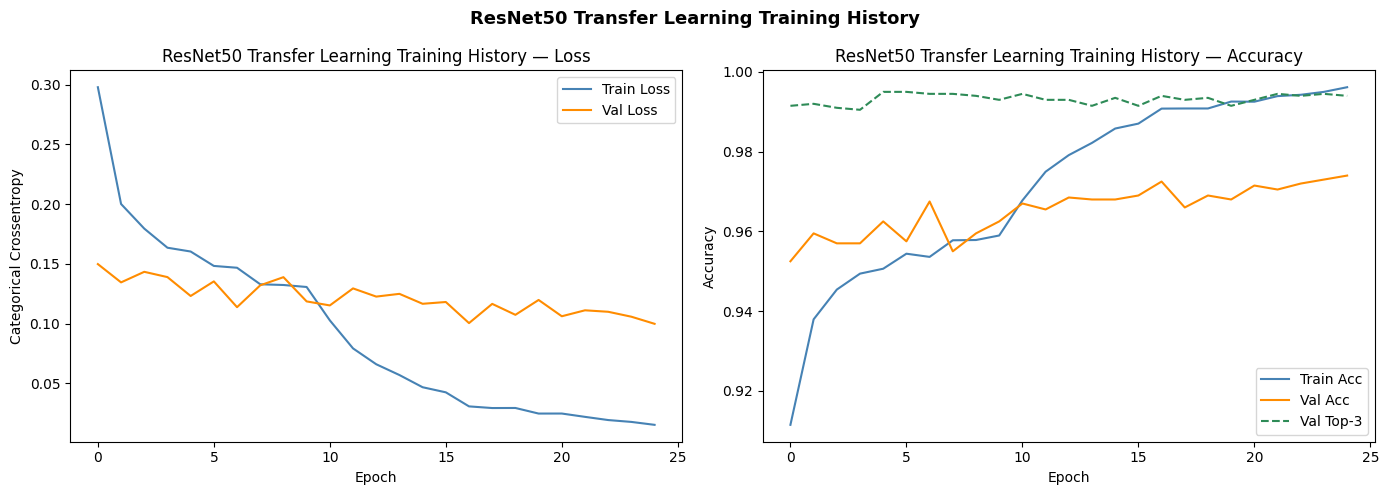

In [19]:
# ── Combine Phase 1 + Phase 2 histories for full ResNet plot ──────────────────
def merge_histories(h1, h2, keys=None):
    if keys is None:
        keys = list(h1.history.keys())
    merged = {k: h1.history[k] + h2.history[k] for k in keys if k in h1.history and k in h2.history}
    class FakeHistory:
        pass
    fh = FakeHistory()
    fh.history = merged
    return fh

history_resnet = merge_histories(history_phase1, history_phase2)
plot_history(history_resnet, 'ResNet50 Transfer Learning Training History',
             'resnet_training_curves.png')

---
**4. Quick Evaluation on Test Set**

In [20]:
# ── CNN test evaluation ───────────────────────────────────────────────────────
cnn_test  = cnn_model.evaluate(test_gen, verbose=1)
res_test  = resnet_model.evaluate(test_gen, verbose=1)

metrics_labels = ['Loss', 'Accuracy', 'Top-3 Accuracy']
eval_df = pd.DataFrame({
    'Metric'   : metrics_labels,
    'Custom CNN'    : cnn_test,
    'ResNet50 TL'   : res_test,
})
print("\n" + "="*55)
print("TEST SET EVALUATION SUMMARY")
print("="*55)
print(eval_df.to_string(index=False))

76/76 [==============================] - 17s 222ms/step - loss: 0.2167 - accuracy: 0.9481 - top3_acc: 0.9896

TEST SET EVALUATION SUMMARY
        Metric  Custom CNN  ResNet50 TL
          Loss    0.880399     0.216741
      Accuracy    0.754051     0.948068
Top-3 Accuracy    0.908600     0.989614


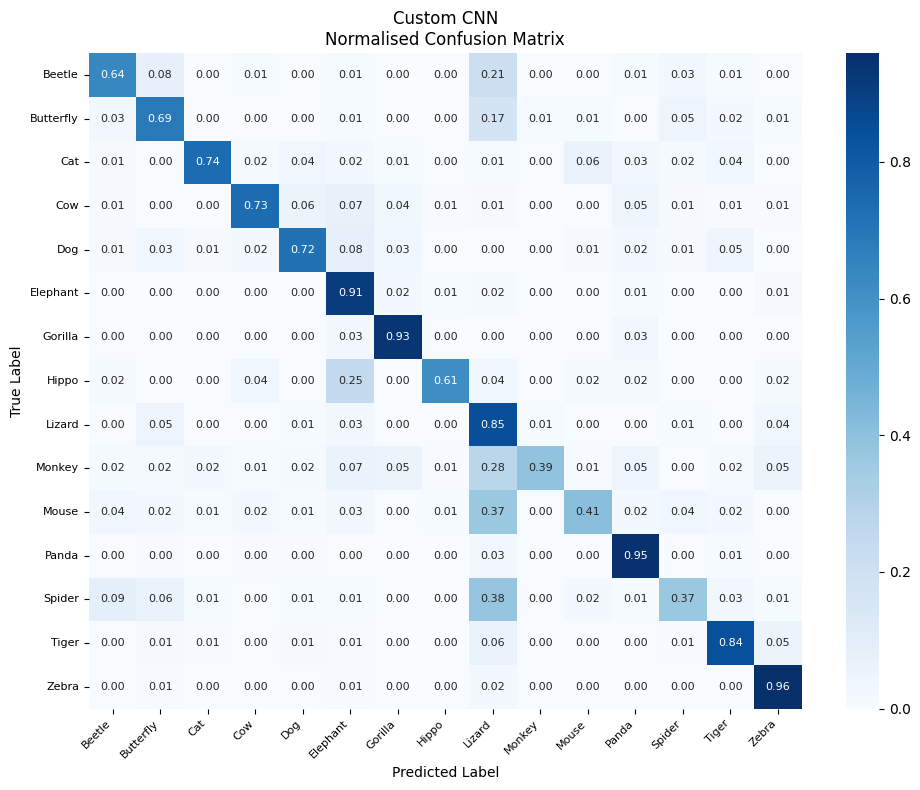


Classification Report — Custom CNN
              precision    recall  f1-score   support

      Beetle       0.70      0.64      0.67       100
   Butterfly       0.67      0.69      0.68       100
         Cat       0.97      0.74      0.84       394
         Cow       0.88      0.73      0.80       177
         Dog       0.64      0.72      0.68        88
    Elephant       0.80      0.91      0.85       306
     Gorilla       0.47      0.93      0.63        30
       Hippo       0.83      0.61      0.71        57
      Lizard       0.30      0.85      0.44       100
      Monkey       0.95      0.39      0.55       184
       Mouse       0.57      0.41      0.48       100
       Panda       0.85      0.95      0.90       237
      Spider       0.61      0.37      0.46       100
       Tiger       0.81      0.84      0.82       164
       Zebra       0.89      0.96      0.92       270

    accuracy                           0.75      2407
   macro avg       0.73      0.72      0.70 

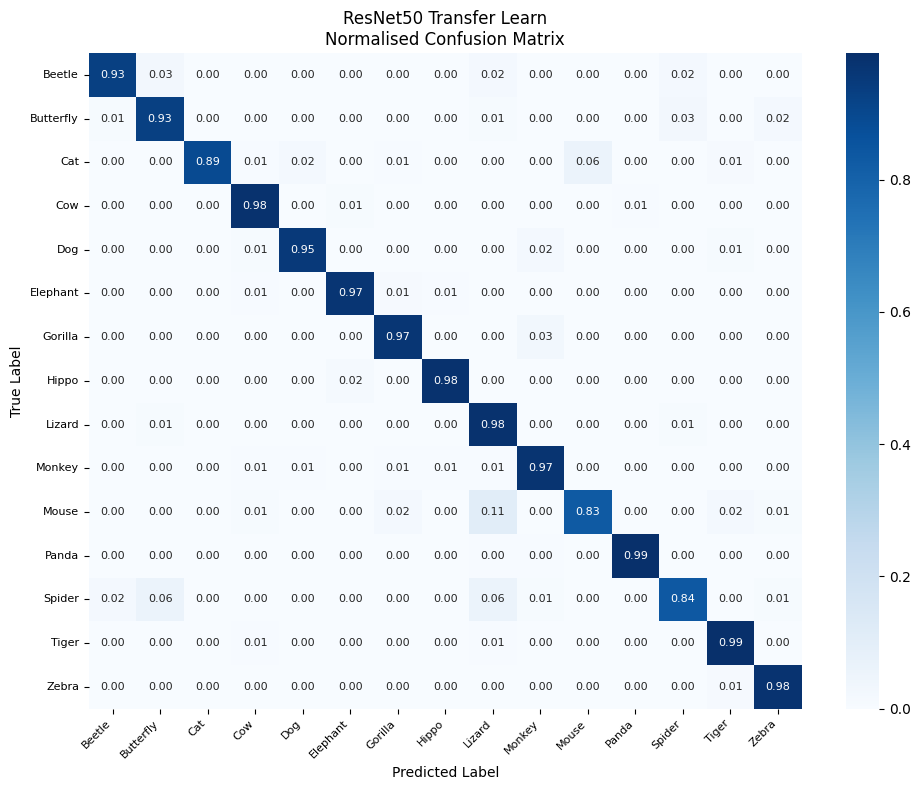


Classification Report — ResNet50 Transfer Learn
              precision    recall  f1-score   support

      Beetle       0.97      0.93      0.95       100
   Butterfly       0.90      0.93      0.92       100
         Cat       1.00      0.89      0.94       394
         Cow       0.96      0.98      0.97       177
         Dog       0.90      0.95      0.93        88
    Elephant       0.98      0.97      0.98       306
     Gorilla       0.76      0.97      0.85        30
       Hippo       0.93      0.98      0.96        57
      Lizard       0.80      0.98      0.88       100
      Monkey       0.97      0.97      0.97       184
       Mouse       0.78      0.83      0.80       100
       Panda       1.00      0.99      0.99       237
      Spider       0.93      0.84      0.88       100
       Tiger       0.93      0.99      0.96       164
       Zebra       0.99      0.98      0.98       270

    accuracy                           0.95      2407
   macro avg       0.92      0.

In [21]:
# ── Confusion matrices ────────────────────────────────────────────────────────
def plot_confusion(model, gen, title, fname):
    gen.reset()
    preds = np.argmax(model.predict(gen, verbose=0), axis=1)
    trues = gen.classes
    cm = confusion_matrix(trues, preds)
    cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)

    fig, ax = plt.subplots(figsize=(10, 8))
    sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Blues',
                xticklabels=CLASSES, yticklabels=CLASSES, ax=ax,
                annot_kws={'size': 8})
    ax.set_xlabel('Predicted Label')
    ax.set_ylabel('True Label')
    ax.set_title(f'{title}\nNormalised Confusion Matrix')
    plt.xticks(rotation=45, ha='right', fontsize=8)
    plt.yticks(rotation=0, fontsize=8)
    plt.tight_layout()
    plt.savefig(fname, dpi=150)
    plt.show()

    print(f"\nClassification Report — {title}")
    print(classification_report(trues, preds, target_names=CLASSES))

plot_confusion(cnn_model,    test_gen, 'Custom CNN',             'confusion_cnn.png')
plot_confusion(resnet_model, test_gen, 'ResNet50 Transfer Learn','confusion_resnet.png')

In [22]:
# ── Save both models for use in Tasks 2, 3, 4 ────────────────────────────────
cnn_model.save('model_custom_cnn.keras')
resnet_model.save('model_resnet_transfer.keras')

# Save training history
import pickle
with open('history_cnn.pkl',    'wb') as f: pickle.dump(history_cnn.history, f)
with open('history_resnet.pkl', 'wb') as f: pickle.dump(history_resnet.history, f)

print("✓  Models and histories saved.")

✓  Models and histories saved.
